# Bài 2 · Biểu diễn văn bản: Bag-of-Words, TF-IDF và chủ đề ẩn

**Thời lượng gợi ý:** 120 phút · **Cần:** Bài 1 · **Không cần GPU**

## Mục tiêu

1. Biến văn bản thành vector bằng **Bag-of-Words (BoW)** và **TF-IDF**; tự cài TF-IDF rồi đối chiếu với scikit-learn.
2. Hiểu ma trận thưa, `n-gram`, `min_df/max_df` và ảnh hưởng của chúng tới kích thước đặc trưng.
3. Đo độ tương tự bằng **cosine** và làm một bộ tìm kiếm câu gần nghĩa đơn giản.
4. Khám phá cấu trúc ẩn bằng **LSA (SVD)** và **NMF**; đọc và đánh giá "chủ đề".
5. Tránh **rò rỉ dữ liệu** khi vector hóa.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import NMF, TruncatedSVD

from nlpvi import LABELS, load_splits, normalize, set_seed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)

train, valid, test = load_splits()
for d in (train, valid, test):
    d["clean"] = d["text"].map(normalize)
print(train[["text", "clean"]].head(3).to_string())

                                                  text                                                clean
0           tư vấn của shop chậm. sẽ không quay lại!!!             tư vấn của shop chậm. sẽ không quay lại!
1                            Thực đơn khá nhiều món!!!                              thực đơn khá nhiều món!
2  Tính năng rất đầy đủ, lại còn ứng dụng rất ổn định.  tính năng rất đầy đủ, lại còn ứng dụng rất ổn định.


## 1. Từ văn bản đến con số

Máy tính chỉ làm việc với số. Ý tưởng đơn giản nhất: **đếm từ**. Mỗi văn bản thành một vector mà mỗi chiều ứng với một từ trong từ điển.

### 1.1 Bag-of-Words bằng tay

In [2]:
docs = [
    "giao hàng nhanh , đóng gói đẹp",
    "giao hàng chậm , đóng gói ẩu",
    "ứng dụng chạy mượt , giao diện đẹp",
    "ứng dụng hay treo , giao diện rối",
]

tokens = [d.split() for d in docs]
tu_dien = sorted({w for t in tokens for w in t})
print("Từ điển:", tu_dien)

def bow(t):
    c = Counter(t)
    return [c[w] for w in tu_dien]

M = np.array([bow(t) for t in tokens])
pd.DataFrame(M, columns=tu_dien, index=[f"văn bản {i}" for i in range(len(docs))])

Từ điển: [',', 'chạy', 'chậm', 'diện', 'dụng', 'giao', 'gói', 'hay', 'hàng', 'mượt', 'nhanh', 'rối', 'treo', 'đóng', 'đẹp', 'ẩu', 'ứng']


,",",chạy,chậm,diện,dụng,giao,gói,hay,hàng,mượt,nhanh,rối,treo,đóng,đẹp,ẩu,ứng
văn bản 0,1,0,0,0,0,1,1,0,1,0,1,0,0,1,1,0,0
văn bản 1,1,0,1,0,0,1,1,0,1,0,0,0,0,1,0,1,0
văn bản 2,1,1,0,1,1,1,0,0,0,1,0,0,0,0,1,0,1
văn bản 3,1,0,0,1,1,1,0,1,0,0,0,1,1,0,0,0,1


Mỗi hàng là một văn bản, mỗi cột là một từ. Hai điều cần để ý:

- **Mất thứ tự**: "chó cắn người" và "người cắn chó" có cùng vector. Vì vậy gọi là "túi từ".
- **Mọi từ có trọng số như nhau**: dấu `,` hay "giao" (xuất hiện ở hầu hết văn bản) có "quyền" ngang với "chậm" (phân biệt được văn bản 1). Đó là vấn đề TF-IDF giải quyết.

### 1.2 TF-IDF: nhấn mạnh từ *đặc trưng*

- **TF** (term frequency): từ xuất hiện càng nhiều trong văn bản này thì càng quan trọng với văn bản này.
- **IDF** (inverse document frequency): từ xuất hiện trong càng ít văn bản thì càng có sức phân biệt.

Công thức mà scikit-learn dùng (mặc định `smooth_idf=True`, chuẩn hóa L2):

$$\text{idf}(t) = \ln\frac{1+n}{1+\text{df}(t)} + 1, \qquad w_{d,t} = \text{tf}_{d,t}\cdot \text{idf}(t), \qquad \mathbf{v}_d \leftarrow \frac{\mathbf{v}_d}{\lVert \mathbf{v}_d \rVert_2}$$

Ta cài đặt đúng công thức này rồi đối chiếu với `TfidfVectorizer`.

In [3]:
n = len(docs)
df_t = (M > 0).sum(axis=0)                       # số văn bản chứa mỗi từ
idf = np.log((1 + n) / (1 + df_t)) + 1           # idf có làm mịn
tfidf = M * idf                                   # tf (đếm thô) × idf
tfidf = tfidf / np.linalg.norm(tfidf, axis=1, keepdims=True)   # chuẩn hóa L2

sk = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b|[^\w\s]").fit(docs)
sk_vec = sk.transform(docs).toarray()

print("Từ điển trùng nhau:", list(sk.get_feature_names_out()) == tu_dien)
print("Sai lệch lớn nhất so với scikit-learn:", np.abs(tfidf - sk_vec).max())

idf_s = pd.Series(idf, index=tu_dien).round(2).sort_values()
print("\nidf thấp nhất (phổ biến):", idf_s.head(3).to_dict())
print("idf cao nhất (hiếm)     :", idf_s.tail(3).to_dict())

Từ điển trùng nhau: True
Sai lệch lớn nhất so với scikit-learn: 0.0

idf thấp nhất (phổ biến): {',': 1.0, 'giao': 1.0, 'dụng': 1.51}
idf cao nhất (hiếm)     : {'treo': 1.92, 'mượt': 1.92, 'ẩu': 1.92}


Sai lệch bằng 0 (hoặc cùng bậc 1e-16 trên máy khác, do làm tròn số thực), tức công thức tự cài trùng khớp. Từ "giao" và dấu "," có idf thấp (xuất hiện ở nhiều văn bản), còn "chậm", "ẩu", "rối" có idf cao (chỉ ở một văn bản) nên được **nhấn mạnh**.

## 2. Trên dữ liệu thật: ma trận thưa

Với 1.262 văn bản và vài trăm từ, ma trận đã phần lớn là số 0. Ta lưu ở dạng **thưa (sparse)** — chỉ giữ các ô khác 0.

In [4]:
cv = CountVectorizer(token_pattern=r"(?u)\b\w+\b|[^\w\s]")
X_counts = cv.fit_transform(train["clean"])
print("Hình dạng:", X_counts.shape, "| kiểu:", type(X_counts).__name__)
print("Số ô khác 0:", X_counts.nnz, f"| mật độ: {X_counts.nnz / np.prod(X_counts.shape):.2%}")
dense_mb = np.prod(X_counts.shape) * 8 / 1e6
sparse_mb = (X_counts.data.nbytes + X_counts.indices.nbytes + X_counts.indptr.nbytes) / 1e6
print(f"Bộ nhớ dạng dày ≈ {dense_mb:.1f} MB, dạng thưa ≈ {sparse_mb:.2f} MB")

Hình dạng: (1262, 585) | kiểu: csr_matrix
Số ô khác 0: 15748 | mật độ: 2.13%
Bộ nhớ dạng dày ≈ 5.9 MB, dạng thưa ≈ 0.19 MB


Với kho văn bản thực (hàng triệu văn bản, hàng trăm nghìn từ) ma trận dạng dày không thể nằm trong RAM — dạng thưa là bắt buộc.

### 2.1 N-gram: tìm lại một phần thứ tự

Bigram (cặp từ liền nhau) cho phép "không tốt" là **một** đặc trưng, khác với "không" và "tốt" riêng lẻ. Cái giá là từ điển phình ra rất nhanh.

In [5]:
rows = []
for ng in [(1, 1), (1, 2), (1, 3)]:
    for min_df in [1, 2, 5]:
        v = TfidfVectorizer(ngram_range=ng, min_df=min_df, token_pattern=r"(?u)\b\w+\b")
        v.fit(train["clean"])
        rows.append({"n-gram": f"{ng[0]}–{ng[1]}", "min_df": min_df, "số đặc trưng": len(v.vocabulary_)})
pd.DataFrame(rows).pivot(index="n-gram", columns="min_df", values="số đặc trưng")

min_df,1,2,5
n-gram,,,
1–1,570,503,409
1–2,3153,1971,1029
1–3,7580,3881,1522


In [6]:
v12 = TfidfVectorizer(ngram_range=(1, 2), min_df=2, token_pattern=r"(?u)\b\w+\b").fit(train["clean"])
ten = v12.get_feature_names_out()
print("Một số bigram bắt được phủ định:", [t for t in ten if t.split()[0] in ("không", "chưa", "chẳng") and " " in t][:12])

Một số bigram bắt được phủ định:

['chưa biết', 'chưa chu', 'chưa dùng', 'chưa nhanh', 'chưa đánh', 'chẳng hề', 'chẳng hợp', 'không chậm', 'không có', 'không gian', 'không hề', 'không hợp']


- `min_df=2`: bỏ các n-gram chỉ xuất hiện ở 1 văn bản (thường là nhiễu hoặc lỗi gõ), cắt giảm đặc trưng mạnh mà ít mất tín hiệu.
- `max_df=0.9`: bỏ các từ có mặt ở > 90% văn bản (gần như không phân biệt).
- Tăng `n` làm từ điển phình ra nhanh; tăng nguy cơ **quá khớp** khi dữ liệu ít.

## 3. Độ tương tự cosine và tìm kiếm câu gần nghĩa

Hai vector càng "cùng hướng" thì văn bản càng giống nhau. Độ đo phổ biến là **cosine** — không phụ thuộc độ dài văn bản:

$$\cos(\mathbf{a},\mathbf{b}) = \frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert}$$

Vì TF-IDF của scikit-learn đã chuẩn hóa L2, cosine chính là tích vô hướng.

In [7]:
tfidf_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, token_pattern=r"(?u)\b\w+\b")
X_tr = tfidf_vec.fit_transform(train["clean"])           # CHỈ fit trên train

def tim_gan_nhat(query, k=5):
    q = tfidf_vec.transform([normalize(query)])
    sim = cosine_similarity(q, X_tr).ravel()
    idx = sim.argsort()[::-1][:k]
    return pd.DataFrame({"cos": sim[idx].round(3), "nhãn": train["label"].iloc[idx].values, "văn bản": train["text"].iloc[idx].values})

tim_gan_nhat("giao hàng chậm quá, thất vọng")

,cos,nhãn,văn bản
0,0.665,tiêu cực,giao hàng chậm.
1,0.378,tiêu cực,Tốc độ giảng quá chậm. Thất vọng.
2,0.371,tiêu cực,Thủ tục chậm. Thất vọng.
3,0.347,tích cực,Giao hàng chậm nhưng bù lại chất lượng quá tốt.
4,0.325,tiêu cực,Giao hàng hơi trễ hẹn và đóng gói hơi ẩu. Thất...


Các kết quả có chung từ ("giao hàng chậm") nên rất giống. Nhưng thử câu **cùng nghĩa khác chữ**:

In [8]:
tim_gan_nhat("shipper tới trễ nhiều ngày")

,cos,nhãn,văn bản
0,0.233,tiêu cực,Giao hàng trễ hẹn.
1,0.169,tích cực,Thời gian xử lý khoảng hai ngày. Phòng ốc cực ...
2,0.161,tiêu cực,Ứng dụng khá nhiều lỗi.
3,0.159,tiêu cực,Thời gian xử lý khoảng hai ngày. Nhân viên khá...
4,0.159,trung tính,Đi công tác nên mình ghé. Thời gian xử lý khoả...


Chỉ từ "trễ" trùng nên điểm cosine rất thấp (cao nhất ~0,23) và các kết quả phía sau gần như ngẫu nhiên: "shipper", "tới", "nhiều ngày" không có trong từ điển hoặc không đặc trưng. Đây là **giới hạn cốt lõi của BoW/TF-IDF**: chúng so khớp *chữ*, không so khớp *nghĩa*. Embedding (Bài 5) và mô hình ngữ cảnh (Bài 9–12) sinh ra để khắc phục điều này.

## 4. Giảm chiều và chủ đề ẩn

### 4.1 LSA: SVD của ma trận TF-IDF

**Latent Semantic Analysis** nén ma trận thưa chiều cao thành vài chiều "ẩn" bằng SVD cắt cụt. Các từ hay đi cùng nhau được gom về cùng một trục.

Tỉ lệ phương sai giữ lại bởi 2 chiều: 0.022


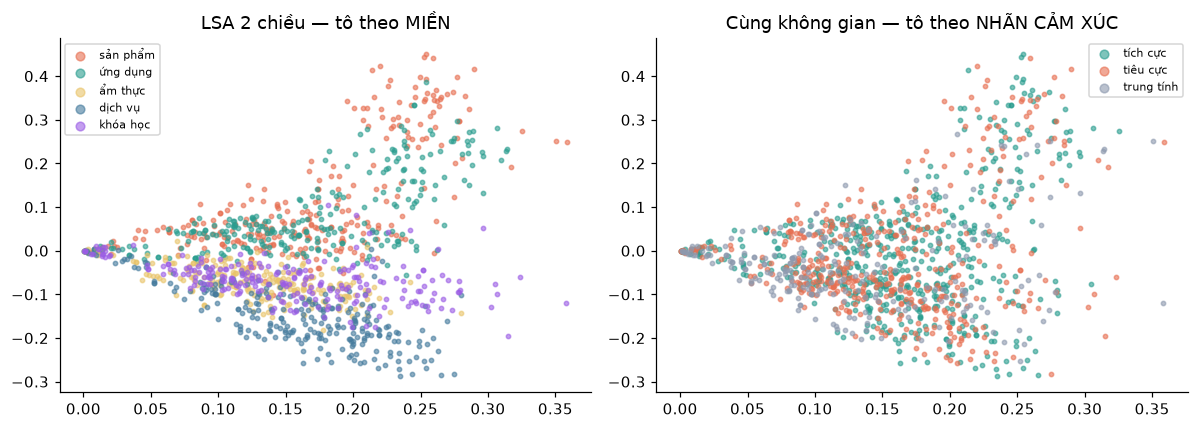

In [9]:
svd = TruncatedSVD(n_components=2, random_state=0)
Z = svd.fit_transform(X_tr)
print("Tỉ lệ phương sai giữ lại bởi 2 chiều:", svd.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
palette = {"sản phẩm": "#e76f51", "ứng dụng": "#2a9d8f", "ẩm thực": "#e9c46a", "dịch vụ": "#457b9d", "khóa học": "#9b5de5"}
for dom, c in palette.items():
    m = (train["domain"] == dom).values
    axes[0].scatter(Z[m, 0], Z[m, 1], s=8, alpha=.6, c=c, label=dom)
axes[0].set_title("LSA 2 chiều — tô theo MIỀN"); axes[0].legend(fontsize=7, markerscale=2)
col = {"tích cực": "#2a9d8f", "tiêu cực": "#e76f51", "trung tính": "#8d99ae"}
for lab, c in col.items():
    m = (train["label"] == lab).values
    axes[1].scatter(Z[m, 0], Z[m, 1], s=8, alpha=.6, c=c, label=lab)
axes[1].set_title("Cùng không gian — tô theo NHÃN CẢM XÚC"); axes[1].legend(fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()

Hai trục đầu của SVD tách được **một phần theo miền** (cột trái: *dịch vụ* nằm phía dưới, *sản phẩm* và *ứng dụng* phía trên, dù còn chồng lấn nhiều) nhưng **không** tách được cảm xúc (cột phải: ba màu trộn lẫn). Lưu ý hai chiều này chỉ giữ ~2% phương sai nên hình chỉ là một lát cắt rất nhỏ. Điều này thường gặp: hướng có nhiều biến thiên nhất (miền) không nhất thiết là thứ ta cần dự đoán (cảm xúc). Đừng suy luận về chất lượng đặc trưng chỉ từ hình 2D.

### 4.2 NMF: chủ đề dễ đọc hơn

**Non-negative Matrix Factorization** phân rã `X ≈ W·H` với mọi phần tử ≥ 0, nên mỗi chủ đề là một *tổ hợp cộng* các từ — dễ diễn giải hơn SVD (có thành phần âm).

In [10]:
tv_u = TfidfVectorizer(min_df=3, max_df=0.5, token_pattern=r"(?u)\b[^\W\d_]{2,}\b")
X_u = tv_u.fit_transform(train["clean"])
terms = tv_u.get_feature_names_out()

nmf = NMF(n_components=5, init="nndsvda", random_state=0, max_iter=500)
W = nmf.fit_transform(X_u)
H = nmf.components_

for k, comp in enumerate(H):
    top = [terms[i] for i in comp.argsort()[::-1][:8]]
    print(f"Chủ đề {k}: " + ", ".join(top))

Chủ đề 0: ăn, liệu, chất, nguyên, giá, khẩu, phần, lượng
Chủ đề 1: hàng, trợ, khách, hỗ, dùng, giao, diện, dụng
Chủ đề 2: tư, vấn, shop, của, tình, nhiệt, thiếu, đóng
Chủ đề 3: giảng, tốc, độ, học, quá, viên, bài, tập
Chủ đề 4: gian, thời, chờ, phòng, ốc, lý, điểm, tục


Đọc các danh sách từ trên và tự đặt tên cho từng chủ đề. Để kiểm tra khách quan, đối chiếu chủ đề chiếm ưu thế của mỗi văn bản với nhãn *miền* thật (mà NMF **không** được thấy):

In [11]:
train["chu_de"] = W.argmax(axis=1)
ct = pd.crosstab(train["chu_de"], train["domain"])
display(ct)

# "độ tinh khiết": phần văn bản thuộc miền chiếm đa số trong mỗi chủ đề
purity = ct.max(axis=1).sum() / ct.values.sum()
print(f"Độ tinh khiết tổng thể: {purity:.1%}")

domain,dịch vụ,khóa học,sản phẩm,ẩm thực,ứng dụng
chu_de,,,,,
0,0,4,89,169,2
1,0,4,86,4,213
2,2,6,91,3,0
3,7,213,3,9,51
4,243,10,10,43,0


Độ tinh khiết tổng thể: 73.6%


Độ tinh khiết chỉ ~74%, và bảng chéo cho thấy lý do: chủ đề của *khóa học* và *dịch vụ* khá "sạch", nhưng *sản phẩm* bị chia vào hai chủ đề (một chủ đề lẫn cả *ẩm thực* vì cùng dùng các từ "giá", "chất lượng"). NMF gom theo **từ hay đi cùng nhau**, chứ không theo nhãn ta đặt. Với dữ liệu thật, hãy dùng thêm chỉ số *coherence* và **luôn đọc mẫu văn bản** của từng chủ đề trước khi tin vào nó. Cũng để ý các "từ" trong danh sách là âm tiết (`nguyên`, `liệu`...) vì ta chưa ghép từ; thử ghép từ ở Bài 1 sẽ cho chủ đề dễ đọc hơn.

## 5. Rò rỉ dữ liệu khi vector hóa

`TfidfVectorizer.fit` học **từ điển và idf từ dữ liệu**. Nếu bạn `fit` trên toàn bộ dữ liệu (cả valid/test) rồi mới chia, thông tin của tập kiểm tra đã lọt vào bước tiền xử lý: từ điển có cả từ chỉ xuất hiện ở test, idf phản ánh thống kê test. Kết quả kiểm tra bị lạc quan.

In [12]:
tat_ca = pd.concat([train, valid, test])["clean"]

v_dung = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b").fit(train["clean"])
v_sai  = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b").fit(tat_ca)

chi_o_ngoai_train = set(v_sai.vocabulary_) - set(v_dung.vocabulary_)
print("Từ điển ĐÚNG (chỉ train):", len(v_dung.vocabulary_))
print("Từ điển SAI (cả 3 tập)  :", len(v_sai.vocabulary_))
print("Từ chỉ xuất hiện ngoài train, nhưng đã 'lọt' vào từ điển:", sorted(chi_o_ngoai_train)[:12])

Từ điển ĐÚNG (chỉ train): 570
Từ điển SAI (cả 3 tập)  : 590
Từ chỉ xuất hiện ngoài train, nhưng đã 'lọt' vào từ điển: ['cau', 'chut', 'cong', 'dai', 'dan', 'gat', 'm', 'mong', 'nao', 'nen', 'nhieu', 'roi']


Quy tắc: **mọi thứ có `fit` đều chỉ được `fit` trên train**; valid/test chỉ được `transform`. Cách chắc chắn nhất là gói vectorizer và mô hình vào một `Pipeline` (Bài 3), để khi cross-validation, mỗi fold tự `fit` lại trên phần train của fold.

## 6. Tổng kết

| Kỹ thuật | Ưu | Nhược |
|---|---|---|
| BoW (đếm) | đơn giản, nhanh | mọi từ ngang nhau; mất thứ tự |
| TF-IDF | nhấn từ đặc trưng; baseline rất mạnh | vẫn mất thứ tự; so khớp chữ chứ không so khớp nghĩa |
| N-gram | bắt cụm ("không tốt") | từ điển phình ra |
| LSA / NMF | nén chiều; chủ đề ẩn | diễn giải cần thận trọng |

**TF-IDF + mô hình tuyến tính** là baseline bạn nên thử *trước tiên* với mọi bài toán phân loại văn bản — nó thường khó thắng hơn mọi người nghĩ.

## Bài tập

1. **(Dễ)** Dùng `CountVectorizer(binary=True)`. Binary khác đếm thô ở đâu? Với đánh giá ngắn, bạn kỳ vọng nó tốt hơn hay kém hơn?
2. **(Dễ)** In 10 từ có idf cao nhất và 10 từ có idf thấp nhất của `tfidf_vec`. Giải thích.
3. **(Vừa)** Cài hàm `cosine(a, b)` thuần NumPy và kiểm tra bằng `cosine_similarity`. Vì sao hai văn bản giống hệt nhau có cosine = 1 còn hai văn bản không chung từ nào có cosine = 0?
4. **(Vừa)** Thử NMF với 3, 5, 8 chủ đề. Chủ đề nào bắt đầu bị chia vụn / trùng lặp?
5. **(Khó)** Thêm đặc trưng ký tự n-gram (`analyzer="char_wb", ngram_range=(2,4)`). Nó giúp tìm kiếm câu "shipper tới trễ" thế nào? Nó có chịu được lỗi gõ và văn bản không dấu không?

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. Binary chỉ ghi "có/không xuất hiện". Với câu ngắn, số lần lặp ít mang thông tin nên binary thường ngang hoặc nhỉnh hơn.
2. idf cao: từ hiếm (thường ít gặp trong một miền). idf thấp: "và", dấu câu, "giao".
3. `a @ b / (np.linalg.norm(a) * np.linalg.norm(b))`. Hai vector không chung chiều nào khác 0 thì tích vô hướng = 0.
4. Khi `n_components` vượt số miền thực (5), chủ đề bị chia theo cảm xúc hoặc theo kiểu câu thay vì theo chủ đề.
5. Char n-gram khớp được các mảnh như "tre", "rễ", nên chịu lỗi gõ/không dấu tốt hơn, nhưng vẫn không hiểu "shipper" ≈ "giao hàng" — vẫn là so khớp bề mặt.
</details>

**Tiếp theo → Bài 3:** huấn luyện bộ phân loại trên các đặc trưng này và đánh giá cho đúng.

**Đọc thêm:** [fastai/course-nlp (tiếng Anh): TF-IDF, NMF, SVD](https://github.com/fastai/course-nlp) · [scikit-learn: Text feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction)